# 01 - Préparation de Flickr8k

Ce notebook est prévu pour Google Colab. Il installe uniquement les outils
nécessaires, charge Flickr8k et affiche un petit sous-ensemble reproductible.
Les images ne sont pas enregistrées dans le dépôt GitHub.

In [1]:
# Installer uniquement la bibliothèque qui peut manquer dans Colab.
!pip -q install datasets

In [ ]:
# Connecter Google Drive et cr?er les dossiers du projet.
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/ia_visuelle")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"R?sultats sauvegard?s dans : {RESULTS_DIR}")

In [2]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd

# Une graine fixe permet de retrouver la même sélection.
SEED = 42
N_IMAGES = 500

# Flickr8k est téléchargé automatiquement par Hugging Face.
dataset = load_dataset("jxie/flickr8k", split="train")
print(f"Nombre total d'images : {len(dataset)}")

README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00000-of-00002-2f8f6bfa852eac(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-2173151d8cd6c7(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-2173151d8cd6c7(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-7025a2b59(…): reconstructing file:   0%|          |  0.00B /  138MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/6000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Nombre total d'images : 6000


In [3]:
# Mélange reproductible puis sélection d'au plus 500 images.
sample_size = min(N_IMAGES, len(dataset))
sample = dataset.shuffle(seed=SEED).select(range(sample_size))
print(f"Images sélectionnées : {len(sample)}")
print(sample.column_names)

Images sélectionnées : 500
['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


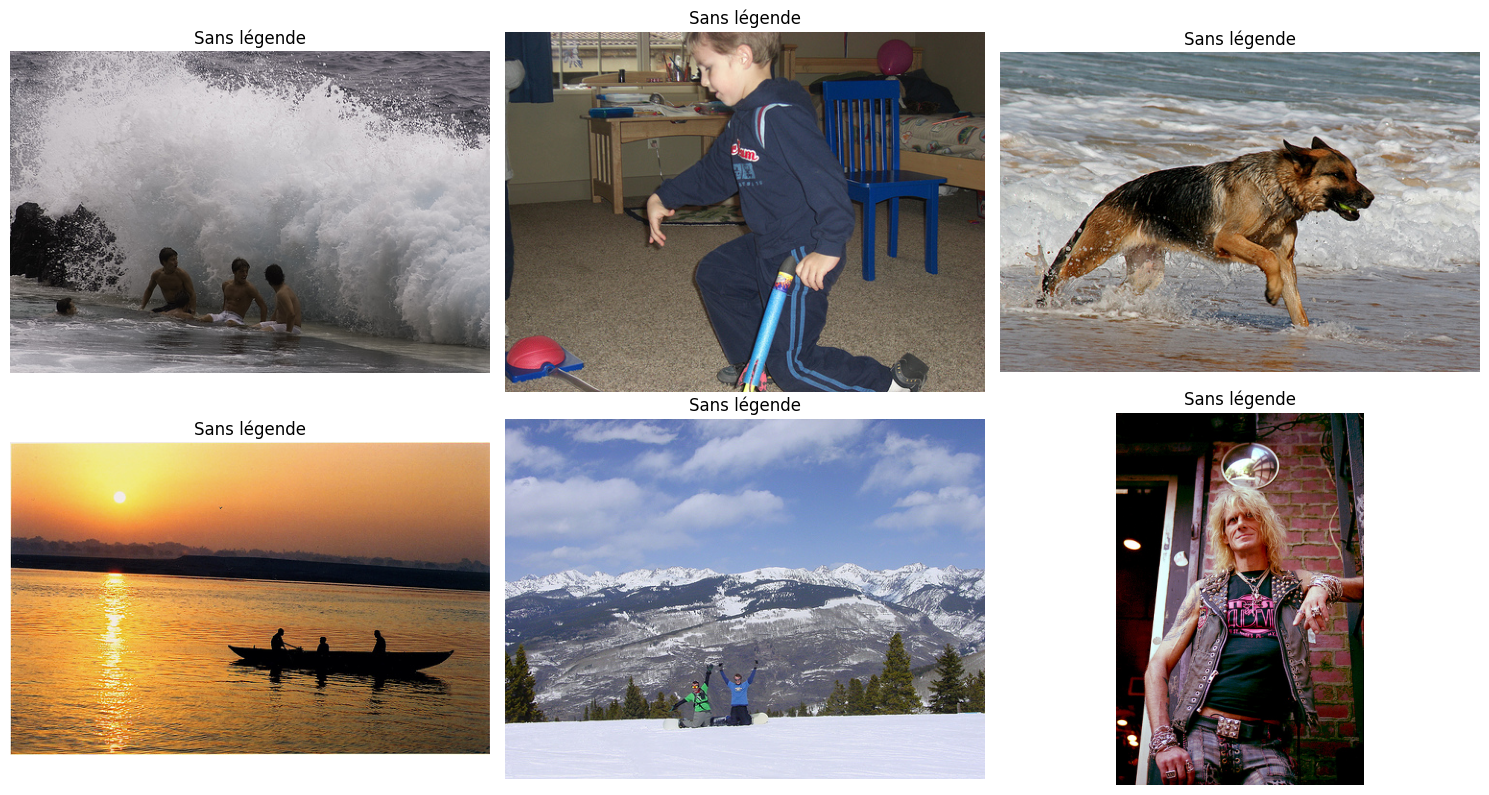

In [4]:
# Affichage de quelques exemples pour vérifier que les données sont correctes.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for index, axis in enumerate(axes.ravel()):
    example = sample[index]
    axis.imshow(example["image"])
    axis.set_title(str(example.get("caption", "Sans légende"))[:80])
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cr?ation d'une table l?g?re avec les cinq l?gendes de r?f?rence.
# Flickr8k contient les colonnes caption_0 ? caption_4.
# Elle reste en m?moire dans Colab et ne sera pas pouss?e dans GitHub.
records = []
for index, example in enumerate(sample):
    record = {"id": index}
    for number in range(5):
        record[f"caption_{number}"] = example[f"caption_{number}"]
    records.append(record)

references = pd.DataFrame(records)
references.head()

In [ ]:
# Sauvegarder automatiquement le CSV dans Google Drive.
output_path = RESULTS_DIR / "flickr8k_references.csv"
references.to_csv(output_path, index=False)
print(f"Fichier cr?? : {output_path}")

## Vérification

Si les images s'affichent correctement, l'étape de préparation est validée.
La prochaine étape ajoutera une baseline avant de charger BLIP et GIT.